# Experiment 4: Hill climbing
Aniruddh Vijayvargia (500125613), Batch D. Lab Manual, Chapter 5.

Steepest-ascent hill climbing on a 1-D landscape and on eight queens,
then random restarts compared with the prediction 1 - (1 - p)^k.

In [1]:
import json, os, platform, random
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10})
R = {"versions": {"python": platform.python_version(), "numpy": np.__version__,
                  "matplotlib": matplotlib.__version__}}

## The landscape, with every local maximum marked, and 1-D hill climbing from several starts

{'local_maxima_x': [0.52, 1.465, 2.765, 5.275, 7.65, 8.855, 9.945], 'local_maxima_f': [0.25, 0.258, 1.023, 0.09, 1.55, -0.445, -0.973], 'global_x': 7.65, 'global_f': 1.55, 'starts': 25, 'starts_reaching_global': 6}


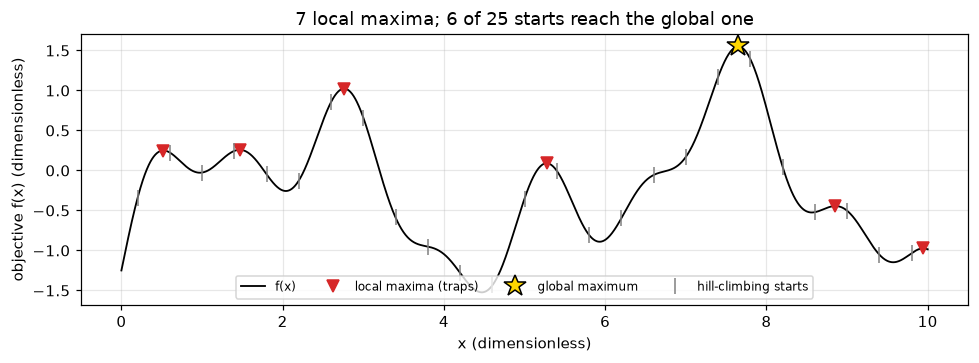

In [2]:
def f(x):
    return np.sin(x) + 0.6 * np.sin(2.7 * x) + 0.35 * np.sin(5.1 * x) - 0.05 * (x - 5) ** 2

xs = np.linspace(0, 10, 2001)
fx = f(xs)
peaks = [i for i in range(1, xs.size - 1) if fx[i] > fx[i - 1] and fx[i] > fx[i + 1]]
g = int(np.argmax(fx))

def climb_1d(x0):
    """Steepest ascent on the grid: move to the better neighbour until none is better."""
    i = int(round(x0 / 10 * (xs.size - 1)))
    while True:
        best = max((j for j in (i - 1, i + 1) if 0 <= j < xs.size), key=lambda j: fx[j])
        if fx[best] <= fx[i]:
            return i
        i = best

starts = np.linspace(0.2, 9.8, 25)
ends = [climb_1d(x0) for x0 in starts]
R["landscape"] = {"local_maxima_x": [round(float(xs[i]), 3) for i in peaks],
                  "local_maxima_f": [round(float(fx[i]), 3) for i in peaks],
                  "global_x": round(float(xs[g]), 3), "global_f": round(float(fx[g]), 3),
                  "starts": len(starts), "starts_reaching_global": int(sum(e == g for e in ends))}
print(R["landscape"])

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(xs, fx, lw=1.2, color="k", label="f(x)")
lm = [i for i in peaks if i != g]
ax.plot(xs[lm], fx[lm], "v", ms=8, color="tab:red", label="local maxima (traps)")
ax.plot(xs[g], fx[g], "*", ms=15, color="gold", mec="k", label="global maximum")
ax.plot(starts, f(starts), "|", ms=10, color="0.5", label="hill-climbing starts")
ax.set_xlabel("x (dimensionless)"); ax.set_ylabel("objective f(x) (dimensionless)")
ax.set_title(f"{len(peaks)} local maxima; {R['landscape']['starts_reaching_global']} of {len(starts)} starts reach the global one")
ax.legend(fontsize=8, loc="lower center", ncol=4); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig4_1_landscape.png")

## Eight queens: plain steepest-ascent hill climbing

In [3]:
def conflicts(board):                       # from Experiment 2
    n, bad = len(board), 0
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                bad += 1
    return bad

def hill_climb(n=8, seed=0):
    """Steepest descent on the number of attacking pairs. True if 0 is reached."""
    r = random.Random(seed)
    board = [r.randrange(n) for _ in range(n)]       # complete random board
    while True:
        current = conflicts(board)
        if current == 0:
            return True
        best, move = current, None
        for c in range(n):                           # every single-queen move
            old = board[c]
            for row in range(n):
                if row == old:
                    continue
                board[c] = row
                v = conflicts(board)
                if v < best:
                    best, move = v, (c, row)
            board[c] = old
        if move is None:
            return False                             # local minimum: stuck
        board[move[0]] = move[1]

def hill_climb_restarts(n=8, restarts=10, seed=0):
    for k in range(restarts):
        if hill_climb(n, seed=seed * 1000 + k):
            return True
    return False

PLAIN_TRIALS = 500
succ = sum(hill_climb(8, seed=s) for s in range(PLAIN_TRIALS))
p = succ / PLAIN_TRIALS
# two independent 200-start measurements, to see the sampling spread
p_a = sum(hill_climb(8, seed=s) for s in range(0, 200)) / 200
p_b = sum(hill_climb(8, seed=s) for s in range(200, 400)) / 200
R["plain"] = {"trials": PLAIN_TRIALS, "successes": succ, "p": p,
              "se": float(np.sqrt(p * (1 - p) / PLAIN_TRIALS)), "p_first200": p_a, "p_second200": p_b}
print(R["plain"])

{'trials': 500, 'successes': 68, 'p': 0.136, 'se': 0.01532997064576446, 'p_first200': 0.125, 'p_second200': 0.155}


{'k': 1, 'trials': 200, 'measured': 0.145, 'predicted': 0.136}


{'k': 2, 'trials': 200, 'measured': 0.255, 'predicted': 0.25350400000000006}


{'k': 5, 'trials': 200, 'measured': 0.56, 'predicted': 0.518530575794176}


{'k': 10, 'trials': 200, 'measured': 0.78, 'predicted': 0.7681871935549123}


{'k': 20, 'trials': 200, 'measured': 0.975, 'predicted': 0.9462628227680523}


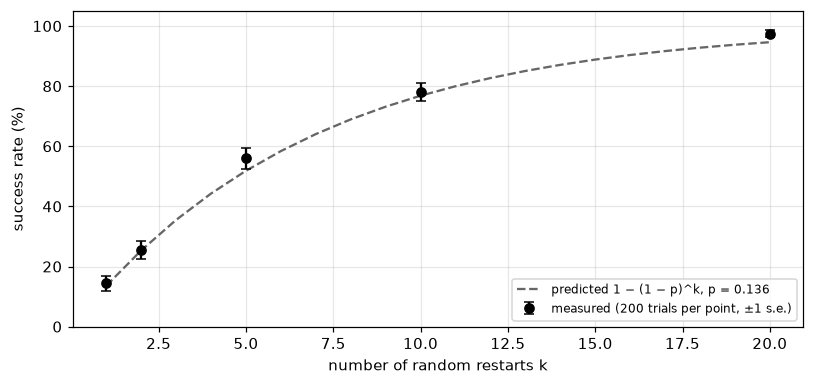

In [4]:
TRIALS = 200
rows = []
for k in (1, 2, 5, 10, 20):
    ok = sum(hill_climb_restarts(8, k, seed=1000 + s) for s in range(TRIALS))
    rows.append({"k": k, "trials": TRIALS, "measured": ok / TRIALS, "predicted": 1 - (1 - p) ** k})
    print(rows[-1])
R["restarts"] = rows
R["k_for_99"] = float(np.log(0.01) / np.log(1 - p))

ks = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(ks, 100 * (1 - (1 - p) ** ks), "--", color="0.4", label=f"predicted 1 − (1 − p)^k, p = {p:.3f}")
meas = np.array([r["measured"] for r in rows])
err = 100 * np.sqrt(meas * (1 - meas) / TRIALS)
ax.errorbar([r["k"] for r in rows], 100 * meas, yerr=err, fmt="o", color="k", capsize=3,
            label=f"measured ({TRIALS} trials per point, ±1 s.e.)")
ax.set_xlabel("number of random restarts k"); ax.set_ylabel("success rate (%)")
ax.set_ylim(0, 105); ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig4_2_restarts.png")

In [5]:
with open("results.json", "w") as fh:
    json.dump(R, fh, indent=2)
print("saved results.json")

saved results.json
